# HITL模式

Human In The Loop人机协同设计模式，它允许计算图在运行过程中暂停，等待人工审批、修正意见或补充信息，然后从暂停位置恢复执行


In [1]:
import os
from typing import Literal, TypedDict

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt
from loguru import logger

_ = load_dotenv(override=True)

In [2]:
llm = ChatOpenAI(
    model=os.environ["model_name"],
    base_url=os.environ["base_url"],
    api_key=os.environ["api_key"],
    temperature=0.7,
)

## 中断

1. 配置检查点存储器

2. 设置 **`thread_id`**

   如果要确保中断后可以恢复执行，就需要保存运行图的完整状态，所以必须**启用可恢复执行**。

3. 在需要中断的位置调用 **`interrupt()`**

In [3]:
class HITLState(TypedDict):
    username: str


def node_a(state: HITLState):
    logger.info("Before: node_a interrupt ")
    username = interrupt("怎么称呼你？")
    logger.info(f"After: node_a interrupt receive {username=}")
    return {"username": username}

In [4]:
graph_builder = StateGraph(state_schema=HITLState)
graph_builder.add_node(node_a)
graph_builder.add_edge(START, "node_a")
graph_builder.add_edge("node_a", END)

graph = graph_builder.compile(checkpointer=InMemorySaver())

In [5]:
config = {"configurable": {"thread_id": "20261021-1"}}

In [6]:
result = graph.invoke({}, config=config)

2026-10-21 17:04:24.112 | INFO     | __main__:node_a:6 - Before: node_a interrupt 


In [7]:
result

{'__interrupt__': [Interrupt(value='怎么称呼你？', id='17302ae897641c36f503a9bf6fd0cc2c', response_schema=None)]}

## 恢复

满足以下要求：

- 基于相同的配置再次调用计算图

- 将输入替换为 **`Command()`** 实例即可恢复运行。

**`LangGraph`** 会从中断节点继续运行，该节点会被再次执行。

通过 **`Command`** 实例的 **`resume`** 属性将用户反馈传递给计算图，中断节点重新运行时，传递给 **`resume`** 属性的值将会作为 **`interrupt()`** 函数的返回值。

In [8]:
msg = result["__interrupt__"][0].value
print(msg)
# 模拟用户手动输入
user_input = "鲨鱼不吃辣椒"

怎么称呼你？


In [9]:
res = graph.invoke(Command(resume=user_input), config=config)
res

2026-10-21 17:04:24.192 | INFO     | __main__:node_a:6 - Before: node_a interrupt 
2026-10-21 17:04:24.194 | INFO     | __main__:node_a:8 - After: node_a interrupt receive username='鲨鱼不吃辣椒'


{'username': '鲨鱼不吃辣椒'}

# 并行中断

In [10]:
class ParallState(TypedDict):
    username: str
    age: int


def node_b(state: HITLState):
    logger.info("Before: node_b interrupt ")
    age = interrupt("请输入您的年龄")
    logger.info(f"After: node_b interrupt recevice {age=}")
    return {"age": int(age)}


graph_builder = StateGraph(state_schema=ParallState)
graph_builder.add_node("node_a", node_a)
graph_builder.add_node("node_b", node_b)
graph_builder.add_edge(START, "node_a")
graph_builder.add_edge(START, "node_b")
graph_builder.add_edge("node_a", END)
graph_builder.add_edge("node_b", END)

graph = graph_builder.compile(checkpointer=InMemorySaver())

In [11]:
res = graph.invoke({}, config=config)

2026-10-21 17:04:24.248 | INFO     | __main__:node_a:6 - Before: node_a interrupt 
2026-10-21 17:04:24.251 | INFO     | __main__:node_b:7 - Before: node_b interrupt 


In [12]:
res

{'__interrupt__': [Interrupt(value='怎么称呼你？', id='f0010a2767df7cf1e8504f20007f42f6', response_schema=None),
  Interrupt(value='请输入您的年龄', id='ffdd50202760f8b0f50aac8d554b1b48', response_schema=None)]}

恢复，根据id进行恢复

In [13]:
resume_map = {}
for item in res["__interrupt__"]:
    if "称呼" in item.value:
        resume_map[item.id] = "鲨鱼不吃辣椒"
    else:
        resume_map[item.id] = 18
resume_map

{'f0010a2767df7cf1e8504f20007f42f6': '鲨鱼不吃辣椒',
 'ffdd50202760f8b0f50aac8d554b1b48': 18}

In [14]:
result = graph.invoke(Command(resume=resume_map), config=config)

2026-10-21 17:04:24.334 | INFO     | __main__:node_a:6 - Before: node_a interrupt 
2026-10-21 17:04:24.339 | INFO     | __main__:node_a:8 - After: node_a interrupt receive username='鲨鱼不吃辣椒'
2026-10-21 17:04:24.338 | INFO     | __main__:node_b:7 - Before: node_b interrupt 
2026-10-21 17:04:24.350 | INFO     | __main__:node_b:9 - After: node_b interrupt recevice age=18


In [15]:
result

{'username': '鲨鱼不吃辣椒', 'age': 18}

# 审批模式

In [16]:
class ApproveState(TypedDict):
    topic: str
    result: str
    is_approved: bool


def approve_node(state: ApproveState) -> Command[Literal["llm_node", "fallback_node"]]:
    """添加返回的类型，用于langgraph生成图"""
    logger.info("执行approve_node")
    is_approved = interrupt("是否同意调用大模型")
    logger.info("授权成功😃" if is_approved else "授权失败😭")
    goto = "llm_node" if is_approved else "fallback_node"
    return Command(update={"is_approved": is_approved}, goto=goto)


def llm_node(state: ApproveState):
    logger.info("执行llm_node")
    ai_msg = llm.invoke(f"列举关于{state['topic']}的三个优点，添加合适的emoji")
    return {"result": ai_msg.content}


def fallback_node(state: ApproveState):
    logger.info("执行fallback_node")
    return {"result": "请求被拒绝"}

In [17]:
graph_builder = StateGraph(state_schema=ApproveState)

graph_builder.add_node(approve_node).add_node(llm_node).add_node(fallback_node)
graph_builder.add_edge(START, "approve_node")
graph_builder.add_edge("llm_node", END)
graph_builder.add_edge("fallback_node", END)

graph = graph_builder.compile(checkpointer=InMemorySaver())

In [18]:
print(graph.get_graph().draw_ascii())

               +-----------+              
               | __start__ |              
               +-----------+              
                     *                    
                     *                    
                     *                    
             +--------------+             
             | approve_node |             
             +--------------+             
              ...          ..             
             .               ..           
           ..                  ..         
+---------------+           +----------+  
| fallback_node |           | llm_node |  
+---------------+           +----------+  
              ***          **             
                 *       **               
                  **   **                 
                +---------+               
                | __end__ |               
                +---------+               


In [19]:
config = {"configurable": {"thread_id": "approve-chat-1"}}
result = graph.invoke({"topic": "Java"}, config=config)

2026-10-21 17:04:24.592 | INFO     | __main__:approve_node:9 - 执行approve_node


In [20]:
print(result)

{'topic': 'Java', '__interrupt__': [Interrupt(value='是否同意调用大模型', id='11dcbde1cc24bafeb5bc7acdfcd142bf', response_schema=None)]}


In [21]:
if "__interrupt__" in result:
    print(result["__interrupt__"][0].value)
    user_answer = "YES"
    # 恢复调用
    result = graph.invoke(Command(resume=(user_answer == "YES")), config=config)
result

2026-10-21 17:04:24.625 | INFO     | __main__:approve_node:9 - 执行approve_node
2026-10-21 17:04:24.627 | INFO     | __main__:approve_node:11 - 授权成功😃
2026-10-21 17:04:24.630 | INFO     | __main__:llm_node:17 - 执行llm_node


是否同意调用大模型


{'topic': 'Java',
 'result': 'Java 的三个优点：\n\n1. ☕🌍 **跨平台性强**：依托 JVM，实现“一次编写，到处运行”，便于部署到不同系统。  \n2. 🧩 **面向对象设计**：封装、继承、多态等特性让代码结构更清晰，利于大型项目开发和维护。  \n3. 📚🛠️ **生态成熟丰富**：类库、框架、开发工具和社区资源非常完善，企业级应用支持强。',
 'is_approved': True}

演示授权失败

In [22]:
config = {"configurable": {"thread_id": "approve-chat-2"}}
result = graph.invoke({"topic": "Python"}, config=config)
result

2026-10-21 17:04:28.963 | INFO     | __main__:approve_node:9 - 执行approve_node


{'topic': 'Python',
 '__interrupt__': [Interrupt(value='是否同意调用大模型', id='4907b15dfac235416b80fcc84d4c5961', response_schema=None)]}

In [23]:
if "__interrupt__" in result:
    print(result["__interrupt__"][0].value)
    # 这次不同意
    user_answer = "NO"
    # 恢复调用
    result = graph.invoke(Command(resume=(user_answer == "YES")), config=config)
result

2026-10-21 17:04:28.985 | INFO     | __main__:approve_node:9 - 执行approve_node
2026-10-21 17:04:28.986 | INFO     | __main__:approve_node:11 - 授权失败😭
2026-10-21 17:04:28.989 | INFO     | __main__:fallback_node:23 - 执行fallback_node


是否同意调用大模型


{'topic': 'Python', 'result': '请求被拒绝', 'is_approved': False}

# 审批与编辑模式

以生成一段代码为例

In [24]:
from langchain.messages import HumanMessage, SystemMessage
from langgraph.graph.message import MessagesState


class ReviewCodeState(MessagesState):
    user_input: str
    generate_code: str
    reviewed_code: str


def gencode_node(state: ReviewCodeState):
    messages = state["messages"] + [HumanMessage(state["user_input"])]
    ai_msg = llm.invoke(messages)
    logger.info("代码生成成功")
    return {"generate_code": ai_msg.content}


def review_node(state: ReviewCodeState):
    reviewed_code = interrupt(
        {"instruct": "请审核生成的代码", "code": state["generate_code"]}
    )
    logger.info("用户审核代码并修改代码")
    return {"reviewed_code": reviewed_code}

In [25]:
graph_builder = StateGraph(state_schema=ReviewCodeState)
graph_builder.add_edge(START, "gencode_node")
graph_builder.add_sequence([gencode_node, review_node])
graph_builder.add_edge("review_node", END)
graph = graph_builder.compile(checkpointer=InMemorySaver())

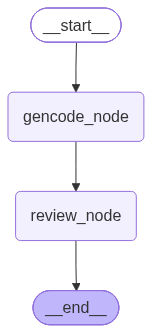

In [26]:
graph

In [27]:
config = {"configurable": {"thread_id": "review-edit-1"}}
result = graph.invoke(
    {
        "user_input": "帮我生成一段初学者初学Java的代码，使用Java新特性Compact Source File",
        "messages": SystemMessage(
            "当用户提出代码生成需求时，直接输出对应代码，不要添加任何解释、说明或客套话，也不要用 ``` 代码块包裹，直接给出纯代码内容。"
        ),
    },
    config=config,
)

2026-10-21 17:04:50.564 | INFO     | __main__:gencode_node:14 - 代码生成成功


In [28]:
result

{'messages': [SystemMessage(content='当用户提出代码生成需求时，直接输出对应代码，不要添加任何解释、说明或客套话，也不要用 ``` 代码块包裹，直接给出纯代码内容。', additional_kwargs={}, response_metadata={}, id='2ff7abc9-1b10-44b9-b307-cfc911e9c83f')],
 'user_input': '帮我生成一段初学者初学Java的代码，使用Java新特性Compact Source File',
 'generate_code': '// 我的第一个 Java 程序 —— 使用 JDK 25 的紧凑源文件（Compact Source File）\n// 文件名：Hello.java\n// 运行方式：java Hello.java\n\nvoid main() {\n    // 1. 最简单的输出\n    IO.println("你好，Java！");\n    IO.println("------------------------------");\n\n    // 2. 变量和基本数据类型\n    String name = "小明";\n    int age = 18;\n    double height = 1.75;\n    boolean isStudent = true;\n\n    IO.println("姓名：" + name);\n    IO.println("年龄：" + age);\n    IO.println("身高：" + height + " 米");\n    IO.println("是学生吗？" + isStudent);\n    IO.println("------------------------------");\n\n    // 3. 条件判断\n    if (age >= 18) {\n        IO.println(name + " 已经成年了");\n    } else {\n        IO.println(name + " 还未成年");\n    }\n\n    // 4. switch 表达式（新写法，不会忘记 break）\n    String l

In [29]:
if "__interrupt__" in result:
    instruct = result["__interrupt__"][0].value["instruct"]
    code = result["__interrupt__"][0].value["code"]
    print(instruct)
    print(code)


请审核生成的代码
// 我的第一个 Java 程序 —— 使用 JDK 25 的紧凑源文件（Compact Source File）
// 文件名：Hello.java
// 运行方式：java Hello.java

void main() {
    // 1. 最简单的输出
    IO.println("你好，Java！");
    IO.println("------------------------------");

    // 2. 变量和基本数据类型
    String name = "小明";
    int age = 18;
    double height = 1.75;
    boolean isStudent = true;

    IO.println("姓名：" + name);
    IO.println("年龄：" + age);
    IO.println("身高：" + height + " 米");
    IO.println("是学生吗？" + isStudent);
    IO.println("------------------------------");

    // 3. 条件判断
    if (age >= 18) {
        IO.println(name + " 已经成年了");
    } else {
        IO.println(name + " 还未成年");
    }

    // 4. switch 表达式（新写法，不会忘记 break）
    String level = switch (age / 10) {
        case 0, 1 -> "少年";
        case 2, 3 -> "青年";
        default -> "其他";
    };
    IO.println(name + " 属于：" + level);
    IO.println("------------------------------");

    // 5. for 循环
    IO.print("数字 1 到 5：");
    for (int i = 1; i <= 5; i++) {
        IO.prin

In [30]:
# 模拟用户修复

review_code_result = """
public class HelloWorld {
    public static void main(String[] args) {
        System.out.println("Hello, World!");
    }
}
"""

result = graph.invoke(Command(resume=review_code_result), config=config)

2026-10-21 17:04:50.622 | INFO     | __main__:review_node:22 - 用户审核代码并修改代码


In [31]:
result

{'messages': [SystemMessage(content='当用户提出代码生成需求时，直接输出对应代码，不要添加任何解释、说明或客套话，也不要用 ``` 代码块包裹，直接给出纯代码内容。', additional_kwargs={}, response_metadata={}, id='2ff7abc9-1b10-44b9-b307-cfc911e9c83f')],
 'user_input': '帮我生成一段初学者初学Java的代码，使用Java新特性Compact Source File',
 'generate_code': '// 我的第一个 Java 程序 —— 使用 JDK 25 的紧凑源文件（Compact Source File）\n// 文件名：Hello.java\n// 运行方式：java Hello.java\n\nvoid main() {\n    // 1. 最简单的输出\n    IO.println("你好，Java！");\n    IO.println("------------------------------");\n\n    // 2. 变量和基本数据类型\n    String name = "小明";\n    int age = 18;\n    double height = 1.75;\n    boolean isStudent = true;\n\n    IO.println("姓名：" + name);\n    IO.println("年龄：" + age);\n    IO.println("身高：" + height + " 米");\n    IO.println("是学生吗？" + isStudent);\n    IO.println("------------------------------");\n\n    // 3. 条件判断\n    if (age >= 18) {\n        IO.println(name + " 已经成年了");\n    } else {\n        IO.println(name + " 还未成年");\n    }\n\n    // 4. switch 表达式（新写法，不会忘记 break）\n    String l

In [32]:
from IPython.display import Markdown, display

generate_code = result.get("generate_code", "无")
reviewed_code = result.get("reviewed_code", "无")

md_text = f"""
### 🤖 AI 生成的代码
```python
{generate_code}
{"_" * 50}
🧑‍💻 人工审核和修改的代码
{reviewed_code}
"""

display(Markdown(md_text))


### 🤖 AI 生成的代码
```python
// 我的第一个 Java 程序 —— 使用 JDK 25 的紧凑源文件（Compact Source File）
// 文件名：Hello.java
// 运行方式：java Hello.java

void main() {
    // 1. 最简单的输出
    IO.println("你好，Java！");
    IO.println("------------------------------");

    // 2. 变量和基本数据类型
    String name = "小明";
    int age = 18;
    double height = 1.75;
    boolean isStudent = true;

    IO.println("姓名：" + name);
    IO.println("年龄：" + age);
    IO.println("身高：" + height + " 米");
    IO.println("是学生吗？" + isStudent);
    IO.println("------------------------------");

    // 3. 条件判断
    if (age >= 18) {
        IO.println(name + " 已经成年了");
    } else {
        IO.println(name + " 还未成年");
    }

    // 4. switch 表达式（新写法，不会忘记 break）
    String level = switch (age / 10) {
        case 0, 1 -> "少年";
        case 2, 3 -> "青年";
        default -> "其他";
    };
    IO.println(name + " 属于：" + level);
    IO.println("------------------------------");

    // 5. for 循环
    IO.print("数字 1 到 5：");
    for (int i = 1; i <= 5; i++) {
        IO.print(i + " ");
    }
    IO.println();

    // 6. while 循环：求 1 到 100 的和
    int sum = 0;
    int i = 1;
    while (i <= 100) {
        sum = sum + i;
        i++;
    }
    IO.println("1 到 100 的和是：" + sum);

    // 7. 数组和增强 for 循环
    String[] fruits = {"苹果", "香蕉", "橙子"};
    IO.print("水果有：");
    for (String fruit : fruits) {
        IO.print(fruit + " ");
    }
    IO.println();
    IO.println("------------------------------");

    // 8. 调用自己写的方法
    IO.println("3 + 5 = " + add(3, 5));
    IO.println("成绩评价：" + describe(92));
    IO.println("成绩评价：" + describe(58));

    // 9. 调用带循环的方法
    printStars(5);
}

// 一个做加法的方法
int add(int a, int b) {
    return a + b;
}

// 根据分数返回评价
String describe(int score) {
    if (score >= 90) {
        return "优秀";
    } else if (score >= 60) {
        return "及格";
    } else {
        return "不及格";
    }
}

// 打印一行星星
void printStars(int count) {
    for (int i = 0; i < count; i++) {
        IO.print("*");
    }
    IO.println();
}
__________________________________________________
🧑‍💻 人工审核和修改的代码

public class HelloWorld {
    public static void main(String[] args) {
        System.out.println("Hello, World!");
    }
}

